Topic: Dog vs Cat Image Classification

This project focuses on developing a deep learning system for classifying images into two categories: Cat and Dog using TensorFlow and Keras. The workflow covers dataset preparation, image augmentation, CNN model development, transfer learning, fine-tuning, model performance comparison, and analysis of incorrectly classified images.

Models Implemented
Custom CNN – A convolutional neural network designed and trained from scratch.
MobileNetV2 – Used as a pre-trained feature extractor for image classification.
EfficientNetB0 – Fine-tuned on the dataset to improve classification performance.

The dataset consists of two classes: Cat and Dog. The training data is split into 80% for training and 20% for validation. The original test set remains separate and is used only for the final evaluation of the trained models.

# Import Libraries

In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    Dropout,
    Flatten,
    Dense
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)



# Function for Test Metrics

In [ ]:

def get_test_metrics(model, test_dataset):


    # Test loss and accuracy
    test_loss, test_accuracy = model.evaluate(
        test_dataset,
        verbose=0
    )

    # Store true labels and predictions
    y_true = []
    y_prob = []

    for images, labels in test_dataset:
        probabilities = model.predict(
            images,
            verbose=0
        ).flatten()

        y_prob.extend(probabilities)
        y_true.extend(labels.numpy().flatten())

    y_true = np.array(y_true).astype(int)
    y_prob = np.array(y_prob)

    y_pred = (y_prob >= 0.5).astype(int)

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    return (
        test_loss,
        test_accuracy,
        precision,
        recall,
        f1
    )

# Function for error analysis

In [ ]:

def error_analysis(
    model,
    test_dataset,
    class_names,
    num_errors=9
):


    # ----------------------------------------
    # Store images, true labels and predictions
    # ----------------------------------------

    all_images = []
    all_true_labels = []
    all_probabilities = []

    for images, labels in test_dataset:

        probabilities = model.predict(
            images,
            verbose=0
        ).flatten()

        all_images.append(images.numpy())
        all_true_labels.append(
            labels.numpy().flatten()
        )
        all_probabilities.append(probabilities)

    all_images = np.concatenate(all_images)
    all_true_labels = np.concatenate(
        all_true_labels
    ).astype(int)

    all_probabilities = np.concatenate(
        all_probabilities
    )

    # ----------------------------------------
    # Convert probability to class prediction
    # ----------------------------------------

    all_pred_labels = (
        all_probabilities >= 0.5
    ).astype(int)

    # ----------------------------------------
    # Classification Report
    # ----------------------------------------

    print("=" * 60)
    print("CLASSIFICATION REPORT")
    print("=" * 60)

    print(
        classification_report(
            all_true_labels,
            all_pred_labels,
            target_names=class_names,
            zero_division=0
        )
    )

    # ----------------------------------------
    # Confusion Matrix
    # ----------------------------------------

    cm = confusion_matrix(
        all_true_labels,
        all_pred_labels
    )

    plt.figure(figsize=(7, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title("Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.show()

    # ----------------------------------------
    # Find Incorrect Predictions
    # ----------------------------------------

    incorrect_indices = np.where(
        all_true_labels != all_pred_labels
    )[0]

    print(
        "Total Incorrect Predictions:",
        len(incorrect_indices)
    )

    if len(incorrect_indices) == 0:
        print("No incorrectly classified images found.")
        return

    # Display at least 9 or all available errors
    num_to_display = min(
        num_errors,
        len(incorrect_indices)
    )

    selected_indices = incorrect_indices[
        :num_to_display
    ]

    # ----------------------------------------
    # Display Incorrect Images
    # ----------------------------------------

    cols = 3
    rows = int(np.ceil(num_to_display / cols))

    plt.figure(
        figsize=(15, 5 * rows)
    )

    for plot_index, image_index in enumerate(
        selected_indices
    ):

        plt.subplot(
            rows,
            cols,
            plot_index + 1
        )

        image = all_images[image_index]

        # Images are already normalized to [0,1]
        plt.imshow(image)

        actual_label = class_names[
            all_true_labels[image_index]
        ]

        predicted_label = class_names[
            all_pred_labels[image_index]
        ]

        probability = all_probabilities[
            image_index
        ]

        # Confidence of predicted class
        if all_pred_labels[image_index] == 1:
            confidence = probability
        else:
            confidence = 1 - probability

        plt.title(
            f"Actual: {actual_label}\n"
            f"Predicted: {predicted_label}\n"
            f"Confidence: {confidence:.2%}"
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()

#Question 1: Dataset Preparation (15 Marks)

## Clone Dataset from Github

In [ ]:
!git clone https://github.com/laxmimerit/dog-cat-full-dataset.git

Cloning into 'dog-cat-full-dataset'...
remote: Enumerating objects: 25059, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 25059 (delta 4), reused 6 (delta 2), pack-reused 25048 (from 1)
Receiving objects: 100% (25059/25059), 541.54 MiB | 28.28 MiB/s, done.
Resolving deltas: 100% (21/21), done.
Updating files: 100% (24990/24990), done.


## Define Dataset Path

In [ ]:
base_dir = "/content/dog-cat-full-dataset/data"
train_dir = os.path.join(base_dir,"train")
test_dir = os.path.join(base_dir,"test")

print("Training Directory:", train_dir)
print("Testing Directory:",test_dir)
print("\n")
print("Training Classes:",os.listdir(train_dir))
print("Testing Classes:",os.listdir(test_dir))

Training Directory: /content/dog-cat-full-dataset/data/train
Testing Directory: /content/dog-cat-full-dataset/data/test


Training Classes: ['cats', 'dogs']
Testing Classes: ['cats', 'dogs']


## count Images in Each Class

In [ ]:


train_cat_count = len(
    glob.glob(os.path.join(train_dir, "cats", "*"))
)

train_dog_count = len(
    glob.glob(os.path.join(train_dir, "dogs", "*"))
)

test_cat_count = len(
    glob.glob(os.path.join(test_dir, "cats", "*"))
)

test_dog_count = len(
    glob.glob(os.path.join(test_dir, "dogs", "*"))
)

print("Training Cats:", train_cat_count)
print("Training Dogs:", train_dog_count)
print("Total Training Images:", train_cat_count + train_dog_count)

print("\nTest Cats:", test_cat_count)
print("Test Dogs:", test_dog_count)
print("Total Test Images:", test_cat_count + test_dog_count)

Training Cats: 10000
Training Dogs: 9989
Total Training Images: 19989

Test Cats: 2500
Test Dogs: 2500
Total Test Images: 5000


##  Load Training and Validation Dataset
# 80% Training / 20% Validation

In [ ]:


IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

# Test dataset is kept completely separate
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

class_names = train_dataset.class_names

print("Class Names:", class_names)

Found 19989 files belonging to 2 classes.
Using 15992 files for training.
Found 19989 files belonging to 2 classes.
Using 3997 files for validation.
Found 5000 files belonging to 2 classes.
Class Names: ['cats', 'dogs']


## Normalize Images to [0, 1]

In [ ]:


normalization_layer = layers.Rescaling(1.0 / 255)

train_dataset = train_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

validation_dataset = validation_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

test_dataset = test_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

print("Images normalized to [0, 1].")

Images normalized to [0, 1].


In [ ]:
for images, labels in train_dataset.take(1):
    print(images[0].numpy())

[[[0.70857847 0.8183824  0.62095594]
  [0.7451134  0.8525391  0.6713772 ]
  [0.70889306 0.81226313 0.65368474]
  ...
  [0.99837685 0.9789244  0.99621254]
  [0.9999388  0.9907361  0.99756056]
  [0.9960785  0.9960785  0.9960785 ]]

 [[0.76398927 0.85924536 0.67657125]
  [0.7759618  0.8680996  0.7013202 ]
  [0.7814492  0.87309563 0.72087604]
  ...
  [0.98020124 0.96358436 0.97568446]
  [0.9999388  0.9922182  0.9960785 ]
  [0.9960785  0.9960785  0.9960785 ]]

 [[0.77936256 0.86045504 0.70845914]
  [0.76954716 0.8506396  0.6986438 ]
  [0.75929135 0.83827525 0.69049644]
  ...
  [0.9663281  0.9822496  0.9672291 ]
  [0.9957683  0.9963887  0.99545807]
  [0.9960785  0.9960785  0.9960785 ]]

 ...

 [[0.5244847  0.53829604 0.5549119 ]
  [0.54206115 0.5533231  0.57248837]
  [0.51520693 0.53449965 0.54563415]
  ...
  [0.4488917  0.61751914 0.40967602]
  [0.49073884 0.65607494 0.4590512 ]
  [0.3909219  0.55625796 0.3592342 ]]

 [[0.505461   0.5172257  0.5503369 ]
  [0.4356233  0.447388   0.48257816]


## Optimize Datasets Using Prefetch
* prefetch() prepares the next batch of images while the model is processing the current batch.
* AUTOTUNE automatically determines the optimal prefetch amount based on available system resources. This reduces waiting time and helps improve training speed and overall dataset performance.

In [ ]:
train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)
validation_dataset = validation_dataset.prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)

In [ ]:
total_images = train_cat_count + train_dog_count
train_samples = int(total_images * 0.80)
validation_samples = total_images - train_samples
test_samples = test_cat_count + test_dog_count

print("Class Names:", class_names)

print("\nNumber of Samples:")
print("Training:", train_samples)
print("Validation:", validation_samples)
print("Test:", test_samples)

Class Names: ['cats', 'dogs']

Number of Samples:
Training: 15991
Validation: 3998
Test: 5000


## Visualization

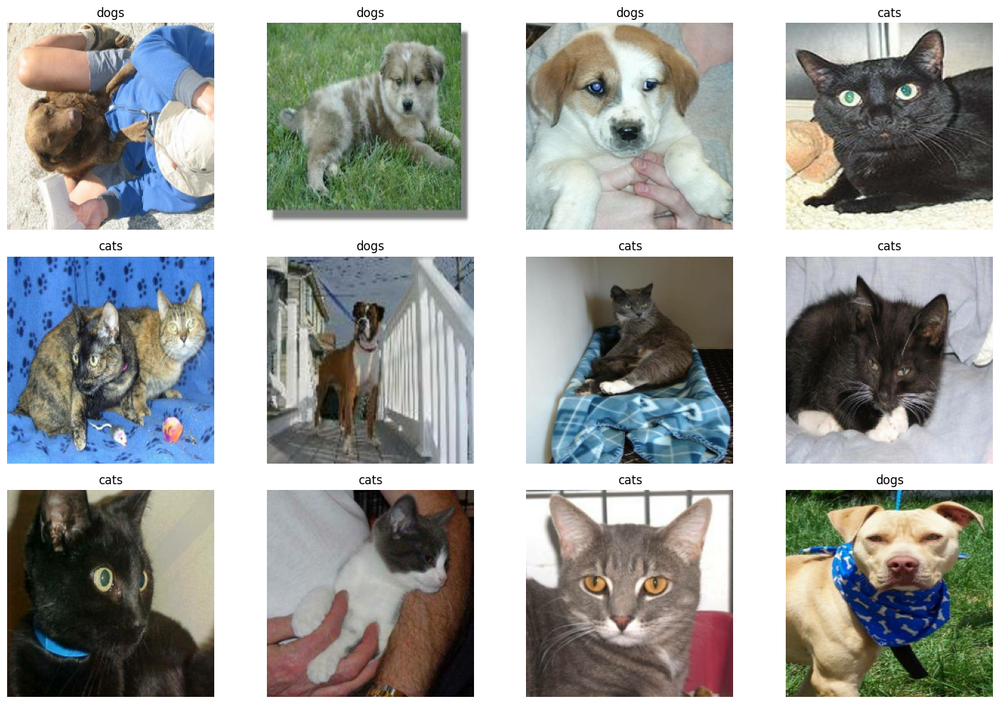

In [ ]:
plt.figure(figsize=(15,10))
for image, labels in train_dataset.take(1):
  for i in range(12):
    plt.subplot(3,4,i+1)
    plt.imshow(image[i].numpy())
    label = int(labels[i].numpy()[0])
    plt.title(class_names[label])
    plt.axis("off")

plt.tight_layout()
plt.show()

# Question 2: Data Augmentation (10 Marks)

## Data Augmentation Pipeline

In [ ]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.15),
        layers.RandomZoom(0.20),
        layers.RandomContrast(0.20)
    ],
    name="data_augmentation"
)

print("Data augmentation pipeline created.")

Data augmentation pipeline created.


## Display One Original Image
# Alongside Four Augmented Versions

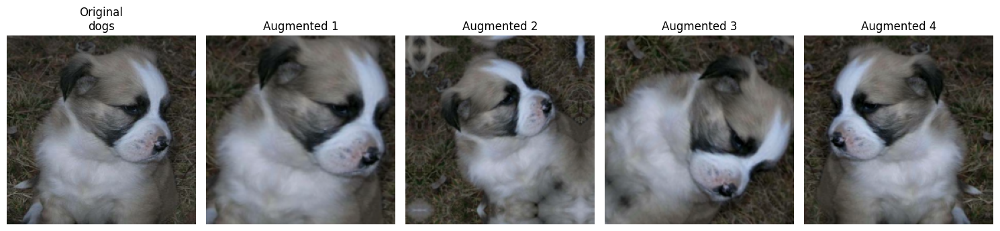

In [ ]:

for images, labels in train_dataset.take(1):
    original_image = images[0]
    original_label = int(labels[0].numpy()[0])

plt.figure(figsize=(15, 6))
plt.subplot(1, 5, 1)
plt.imshow(original_image)
plt.title("Original\n" + class_names[original_label])
plt.axis("off")

for i in range(4):
    augmented_image = data_augmentation(
        tf.expand_dims(original_image, axis=0),
        training=True
    )[0]

    plt.subplot(1, 5, i + 2)
    plt.imshow(augmented_image.numpy())
    plt.title(f"Augmented {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

# Question 3: Custom CNN Model (20 Marks)

## Custom CNN Model

In [ ]:


custom_cnn = Sequential([

    # Data augmentation is used only during training
    data_augmentation,

    # Block 1
    Conv2D(32, (3, 3), activation="relu", padding="same",
           input_shape=(224, 224, 3)),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    # Block 2
    Conv2D(64, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    # Block 3
    Conv2D(128, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.30),

    # Block 4
    Conv2D(256, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.30),

    # Classification Head
    Flatten(),
    Dense(256, activation="relu"),
    BatchNormalization(),
    Dropout(0.50),

    # Binary classification
    Dense(1, activation="sigmoid")
])

custom_cnn.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## Compile

In [ ]:
custom_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

## Early Stopping

In [ ]:

early_stopping_cnn = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)


## Save the best model weights

In [ ]:

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath="/content/drive/MyDrive/Cat and dog/CNN//best_custom_cnn.weights.h5",
    monitor="val_accuracy",
    save_best_only=True,
    save_weights_only=True,
    mode="max",
    verbose=1
)


## Model Training

In [ ]:

EPOCHS = 30

history_cnn = custom_cnn.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=[early_stopping_cnn, checkpoint]
)

Epoch 1/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.5962 - loss: 0.8138
Epoch 1: val_accuracy improved from None to 0.12534, saving model to /content/drive/MyDrive/Cat and dog/CNN//best_custom_cnn.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/Cat and dog/CNN//best_custom_cnn.weights.h5
500/500 ━━━━━━━━━━━━━━━━━━━━ 107s 190ms/step - accuracy: 0.6256 - loss: 0.7277 - val_accuracy: 0.1253 - val_loss: 1.6793
Epoch 2/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step - accuracy: 0.6828 - loss: 0.6066
Epoch 2: val_accuracy improved from 0.12534 to 0.41456, saving model to /content/drive/MyDrive/Cat and dog/CNN//best_custom_cnn.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/Cat and dog/CNN//best_custom_cnn.weights.h5
500/500 ━━━━━━━━━━━━━━━━━━━━ 95s 191ms/step - accuracy: 0.6944 - loss: 0.5877 - val_accuracy: 0.4146 - val_loss: 1.0642
Epoch 3/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - accuracy: 0.7124 - loss: 0.5542
Epoch 3: val_acc

## Accuracy and Loss Curve

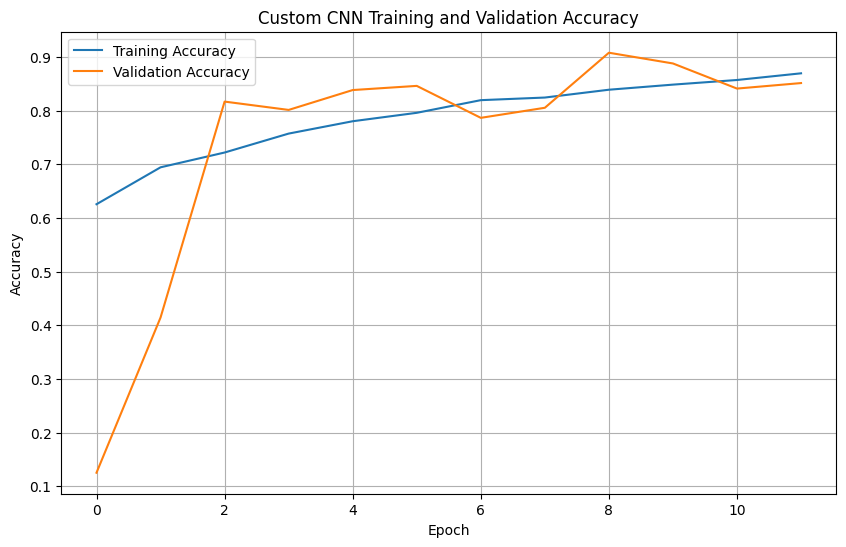

In [ ]:


plt.figure(figsize=(10, 6))

plt.plot(
    history_cnn.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_cnn.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Custom CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

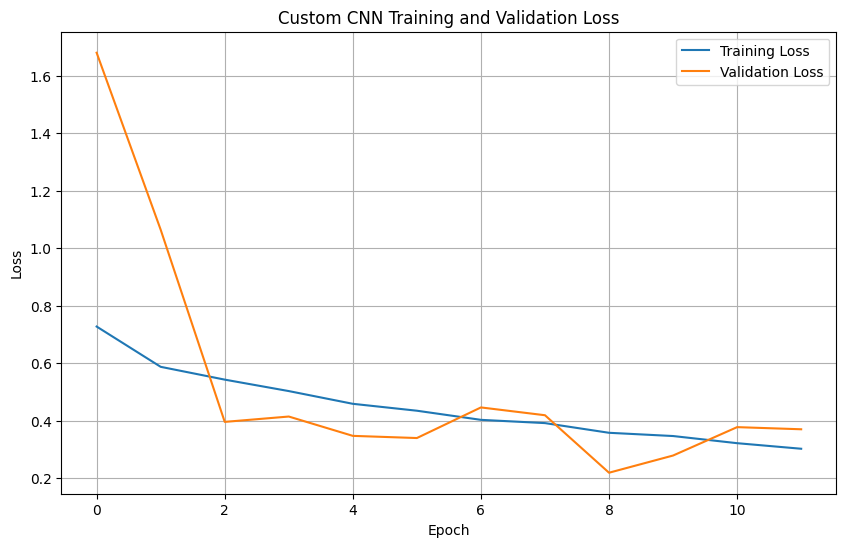

In [ ]:


plt.figure(figsize=(10, 6))

plt.plot(
    history_cnn.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_cnn.history["val_loss"],
    label="Validation Loss"
)

plt.title("Custom CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

## Performance Measure

In [ ]:
cnn_test_loss, cnn_test_accuracy, cnn_precision, cnn_recall, cnn_f1 = \
    get_test_metrics(custom_cnn, test_dataset)

print("Custom CNN")
print("Test Loss:", cnn_test_loss)
print("Test Accuracy:", cnn_test_accuracy)
print("Test Precision:", cnn_precision)
print("Test Recall:", cnn_recall)
print("Test F1:", cnn_f1)

Custom CNN
Test Loss: 0.36454230546951294
Test Accuracy: 0.843999981880188
Test Precision: 0.8080229226361032
Test Recall: 0.9024
Test F1: 0.8526077097505669


In [ ]:
y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = custom_cnn.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend((predictions > 0.5).astype(int).flatten())

# Convert to NumPy arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

# Print results
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.844
Precision: 0.8080229226361032
Recall   : 0.9024
F1 Score : 0.8526077097505669


## Classification Report

In [ ]:
print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    target_names=["Cat", "Dog"]
))


Classification Report:

              precision    recall  f1-score   support

         Cat       0.89      0.79      0.83      2500
         Dog       0.81      0.90      0.85      2500

    accuracy                           0.84      5000
   macro avg       0.85      0.84      0.84      5000
weighted avg       0.85      0.84      0.84      5000



## Confusion Matrix

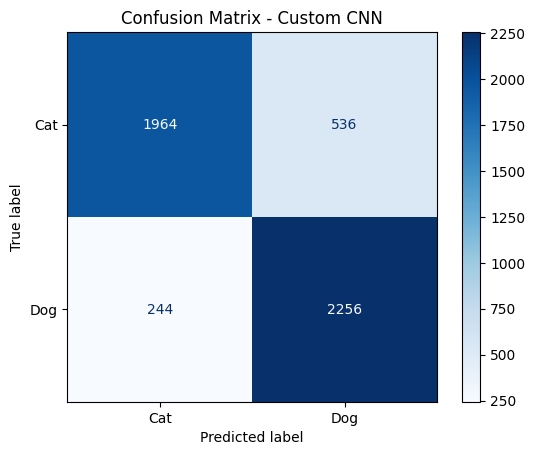

In [ ]:
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Custom CNN")
plt.show()

## Save Model

In [ ]:
custom_cnn.save("/content/drive/MyDrive/Cat and dog/CNN/custom_cnn.keras")

print("Model saved successfully.")

Model saved successfully.


# Question 4: Transfer Learning / Feature Extraction (20 Marks)

## MobileNet Model

In [ ]:

mobilenet_base = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

mobilenet_base.trainable = False

print("Total MobileNetV2 layers:", len(mobilenet_base.layers))
print("Backbone trainable:", mobilenet_base.trainable)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total MobileNetV2 layers: 154
Backbone trainable: False


In [ ]:
mobilenet_model = Sequential([
    layers.Lambda(
        lambda x: tf.keras.applications.mobilenet_v2.preprocess_input(
            x * 255.0
        )
    ),

    mobilenet_base,

    layers.GlobalAveragePooling2D(),

    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.40),

    Dense(1, activation="sigmoid")
])

mobilenet_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

## compile

In [ ]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 feature extraction model compiled.")

MobileNetV2 feature extraction model compiled.


## Early Stop

In [ ]:
early_stopping_mobilenet = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

## Model Training

In [ ]:

checkpoint_mobilenet = tf.keras.callbacks.ModelCheckpoint(
    filepath="/content/drive/MyDrive/Cat and dog/MobileNetV2/best_mobilenet.weights.h5",
    monitor="val_accuracy",
    save_best_only=True,
    save_weights_only=True,
    mode="max",
    verbose=1
)



In [ ]:
history_mobilenet = mobilenet_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=15,
    callbacks=[early_stopping_mobilenet, checkpoint_mobilenet]
)

Epoch 1/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9732 - loss: 0.0708
Epoch 1: val_accuracy improved from None to 0.99575, saving model to /content/drive/MyDrive/Cat and dog/MobileNetV2/best_mobilenet.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/Cat and dog/MobileNetV2/best_mobilenet.weights.h5
500/500 ━━━━━━━━━━━━━━━━━━━━ 83s 133ms/step - accuracy: 0.9814 - loss: 0.0521 - val_accuracy: 0.9957 - val_loss: 0.0163
Epoch 2/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.9909 - loss: 0.0319
Epoch 2: val_accuracy did not improve from 0.99575
500/500 ━━━━━━━━━━━━━━━━━━━━ 47s 94ms/step - accuracy: 0.9892 - loss: 0.0343 - val_accuracy: 0.9907 - val_loss: 0.0266
Epoch 3/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.9909 - loss: 0.0282
Epoch 3: val_accuracy did not improve from 0.99575
500/500 ━━━━━━━━━━━━━━━━━━━━ 65s 60ms/step - accuracy: 0.9906 - loss: 0.0280 - val_accuracy: 0.9952 - val_loss: 0.0181
Epoch 4/15
499/500 ━━━━━━━━━━

## Accuracy and Loss Curve

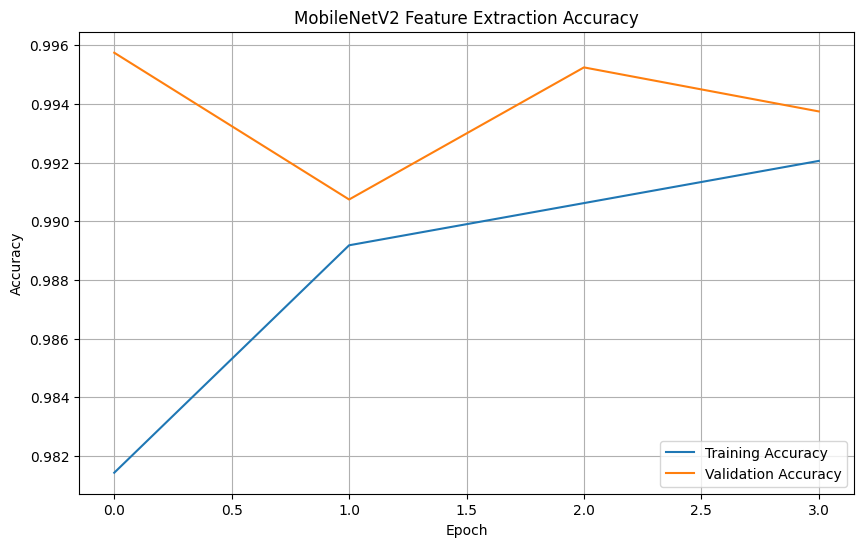

In [ ]:

plt.figure(figsize=(10, 6))

plt.plot(
    history_mobilenet.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_mobilenet.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("MobileNetV2 Feature Extraction Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

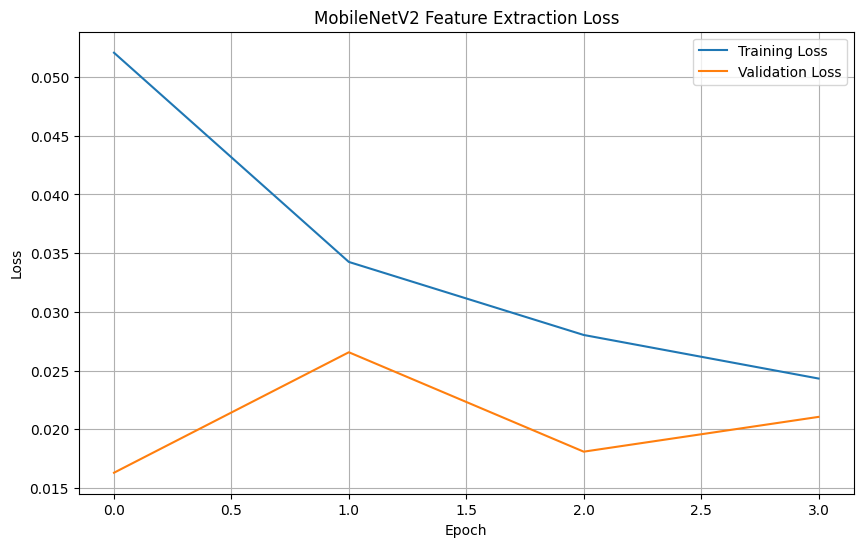

In [ ]:


plt.figure(figsize=(10, 6))

plt.plot(
    history_mobilenet.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_mobilenet.history["val_loss"],
    label="Validation Loss"
)

plt.title("MobileNetV2 Feature Extraction Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

## Performance Measure

In [ ]:


mobilenet_test_loss, mobilenet_test_accuracy, mobilenet_precision, \
mobilenet_recall, mobilenet_f1 = get_test_metrics(
    mobilenet_model,
    test_dataset
)

print("MobileNetV2 Feature Extraction")
print("Test Loss:", mobilenet_test_loss)
print("Test Accuracy:", mobilenet_test_accuracy)
print("Test Precision:", mobilenet_precision)
print("Test Recall:", mobilenet_recall)
print("Test F1:", mobilenet_f1)

MobileNetV2 Feature Extraction
Test Loss: 0.03721213340759277
Test Accuracy: 0.9865999817848206
Test Precision: 0.9814008705975465
Test Recall: 0.992
Test F1: 0.9866719713546847


## Classification Report

In [ ]:
# Get true labels and predictions
y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = mobilenet_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend((predictions > 0.5).astype(int).flatten())

# Convert to NumPy arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)


In [ ]:
print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    target_names=["Cat", "Dog"]
))


Classification Report:

              precision    recall  f1-score   support

         Cat       0.99      0.98      0.99      2500
         Dog       0.98      0.99      0.99      2500

    accuracy                           0.99      5000
   macro avg       0.99      0.99      0.99      5000
weighted avg       0.99      0.99      0.99      5000



## Confusion Matrix

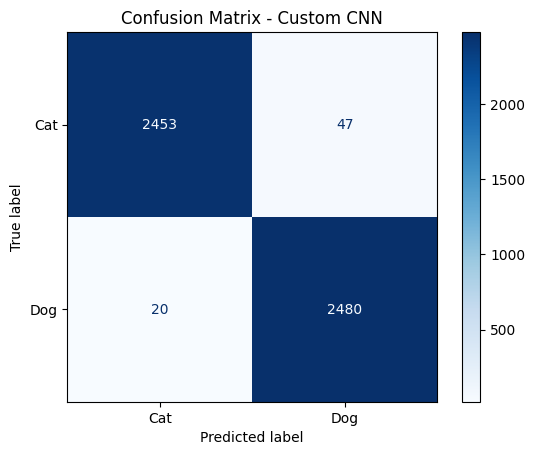

In [ ]:
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Custom CNN")
plt.show()

## Save Model

In [ ]:
mobilenet_model.save("/content/drive/MyDrive/Cat and dog/MobileNetV2/MobileNetV2.keras")

print("Model saved successfully.")

Model saved successfully.


# Question 5: Fine Tuning

##EfficientNetB0 Model

In [ ]:
efficientnet_base = tf.keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

print("EfficientNetB0 loaded.")
print("Total layers:", len(efficientnet_base.layers))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 loaded.
Total layers: 238


In [ ]:
efficientnet_model = Sequential([

    # Convert normalized [0, 1] images back to [0, 255]
    layers.Lambda(lambda x: x * 255.0),

    efficientnet_base,

    layers.GlobalAveragePooling2D(),

    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.40),

    Dense(1, activation="sigmoid")
])

# Unfreeze all layers for full fine-tuning
efficientnet_base.trainable = True

print("EfficientNetB0 backbone trainable:",
      efficientnet_base.trainable)

efficientnet_model.summary()

EfficientNetB0 backbone trainable: True


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda_1 (Lambda)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,049,571 (15.45 MB)

 Trainable params: 4,007,548 (15.29 MB)

 Non-trainable params: 42,023 (164.16 KB)

## Compile

In [ ]:
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNetB0 compiled for full fine-tuning.")

EfficientNetB0 compiled for full fine-tuning.


## Early Stop

In [ ]:
early_stopping_efficientnet = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [ ]:
checkpoint_efficientNetb0 = tf.keras.callbacks.ModelCheckpoint(
    filepath="/content/drive/MyDrive/Cat and dog/efficientNetb0/best_efficientNetb0.weights.h5",
    monitor="val_accuracy",
    save_best_only=True,
    save_weights_only=True,
    mode="max",
    verbose=1
)


## Model Training

In [ ]:
history_efficientnet = efficientnet_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=15,
    callbacks=[early_stopping_efficientnet,checkpoint_efficientNetb0]
)

Epoch 1/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 289ms/step - accuracy: 0.7079 - loss: 0.6065
Epoch 1: val_accuracy improved from None to 0.94796, saving model to /content/drive/MyDrive/Cat and dog/efficientNetb0/best_efficientNetb0.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/Cat and dog/efficientNetb0/best_efficientNetb0.weights.h5
500/500 ━━━━━━━━━━━━━━━━━━━━ 314s 336ms/step - accuracy: 0.8164 - loss: 0.4004 - val_accuracy: 0.9480 - val_loss: 0.1343
Epoch 2/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.9286 - loss: 0.1770
Epoch 2: val_accuracy improved from 0.94796 to 0.97473, saving model to /content/drive/MyDrive/Cat and dog/efficientNetb0/best_efficientNetb0.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/Cat and dog/efficientNetb0/best_efficientNetb0.weights.h5
500/500 ━━━━━━━━━━━━━━━━━━━━ 76s 152ms/step - accuracy: 0.9345 - loss: 0.1641 - val_accuracy: 0.9747 - val_loss: 0.0709
Epoch 3/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms

## Accuracy Curve and Loss Curve

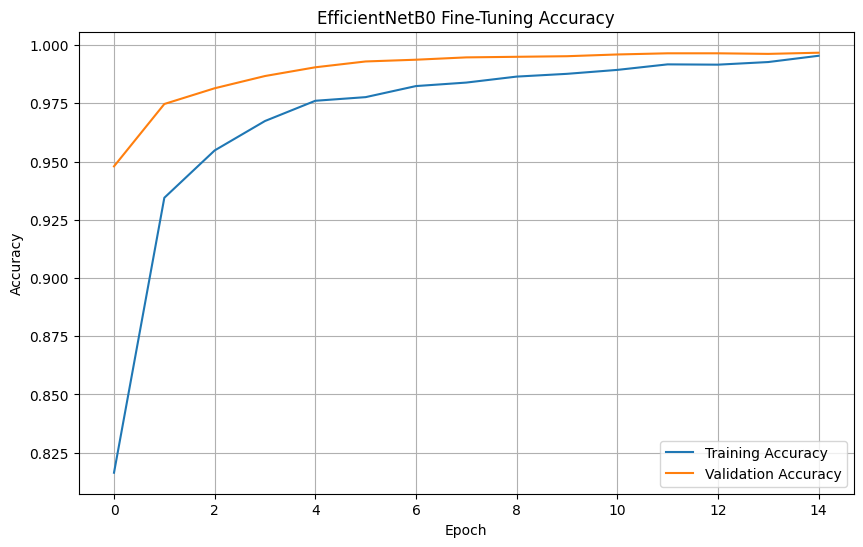

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    history_efficientnet.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_efficientnet.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("EfficientNetB0 Fine-Tuning Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

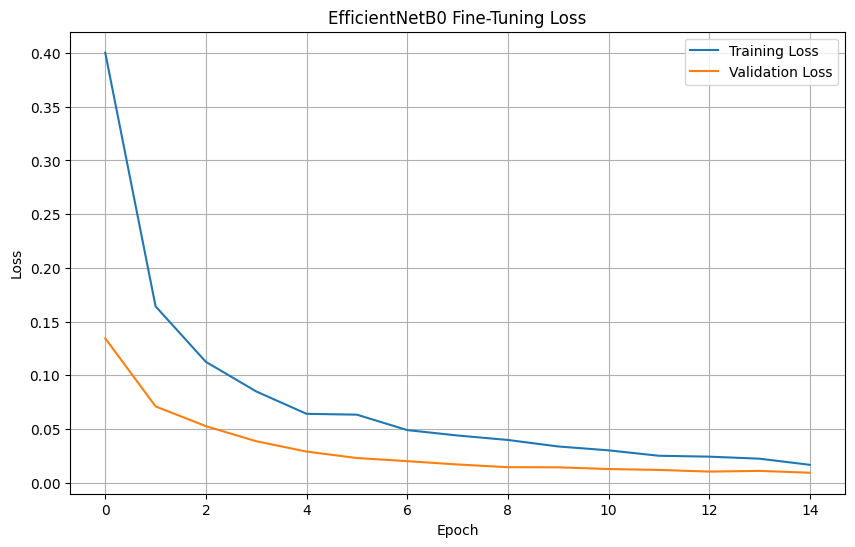

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    history_efficientnet.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_efficientnet.history["val_loss"],
    label="Validation Loss"
)

plt.title("EfficientNetB0 Fine-Tuning Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

## Performance Measure

In [ ]:
efficientnet_test_loss, efficientnet_test_accuracy, \
efficientnet_precision, efficientnet_recall, efficientnet_f1 = \
    get_test_metrics(
        efficientnet_model,
        test_dataset
    )

print("EfficientNetB0 Fine-Tuning")
print("Test Loss:", efficientnet_test_loss)
print("Test Accuracy:", efficientnet_test_accuracy)
print("Test Precision:", efficientnet_precision)
print("Test Recall:", efficientnet_recall)
print("Test F1:", efficientnet_f1)

EfficientNetB0 Fine-Tuning
Test Loss: 0.02607744187116623
Test Accuracy: 0.9908000230789185
Test Precision: 0.9904076738609112
Test Recall: 0.9912
Test F1: 0.9908036785285885


## Classification Report

In [ ]:
# Get true labels and predictions
y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = mobilenet_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend((predictions > 0.5).astype(int).flatten())

# Convert to NumPy arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)


In [ ]:
print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    target_names=["Cat", "Dog"]
))


Classification Report:

              precision    recall  f1-score   support

         Cat       0.99      0.98      0.99      2500
         Dog       0.98      0.99      0.99      2500

    accuracy                           0.99      5000
   macro avg       0.99      0.99      0.99      5000
weighted avg       0.99      0.99      0.99      5000



## Confusion Matrix

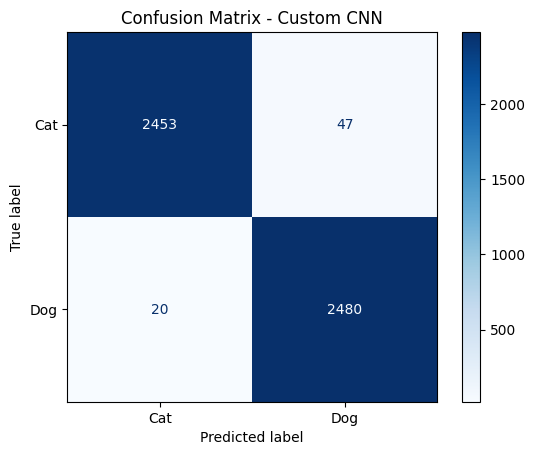

In [ ]:
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Custom CNN")
plt.show()

## Save Model

In [ ]:
mobilenet_model.save("/content/drive/MyDrive/Cat and dog/efficientNetb0/efficientNetb0.keras")

print("Model saved successfully.")

Model saved successfully.


# Question 6: Model Comparison (10 Marks)

## Comparision Table

In [ ]:
comparison_table = pd.DataFrame({

    "Model": [
        "Custom CNN",
        "MobileNetV2 Feature Extraction",
        "EfficientNetB0 Fine-Tuning"
    ],

    "Total Parameters": [
        custom_cnn.count_params(),
        mobilenet_model.count_params(),
        efficientnet_model.count_params()
    ],

    "Training Loss": [
        history_cnn.history["loss"][-1],
        history_mobilenet.history["loss"][-1],
        history_efficientnet.history["loss"][-1]
    ],

    "Training Accuracy": [
        history_cnn.history["accuracy"][-1],
        history_mobilenet.history["accuracy"][-1],
        history_efficientnet.history["accuracy"][-1]
    ],

    "Validation Loss": [
        history_cnn.history["val_loss"][-1],
        history_mobilenet.history["val_loss"][-1],
        history_efficientnet.history["val_loss"][-1]
    ],

    "Validation Accuracy": [
        history_cnn.history["val_accuracy"][-1],
        history_mobilenet.history["val_accuracy"][-1],
        history_efficientnet.history["val_accuracy"][-1]
    ],

    "Test Loss": [
        cnn_test_loss,
        mobilenet_test_loss,
        efficientnet_test_loss
    ],

    "Test Accuracy": [
        cnn_test_accuracy,
        mobilenet_test_accuracy,
        efficientnet_test_accuracy
    ],

    "Test Precision": [
        cnn_precision,
        mobilenet_precision,
        efficientnet_precision
    ],

    "Test Recall": [
        cnn_recall,
        mobilenet_recall,
        efficientnet_recall
    ],

    "Test F1 Score": [
        cnn_f1,
        mobilenet_f1,
        efficientnet_f1
    ]
})

# Round numerical values
comparison_table.round(4)

,Model,Total Parameters,Training Loss,Training Accuracy,Validation Loss,Validation Accuracy,Test Loss,Test Accuracy,Test Precision,Test Recall,Test F1 Score
0,Custom CNN,13236929,0.3030,0.8696,0.3707,0.8514,0.3645,0.8440,0.8080,0.9024,0.8526
1,MobileNetV2 Feature Extraction,2422593,0.0243,0.9921,0.0211,0.9937,0.0372,0.9866,0.9814,0.9920,0.9867
2,EfficientNetB0 Fine-Tuning,4214180,0.0165,0.9954,0.0091,0.9967,0.0261,0.9908,0.9904,0.9912,0.9908


Discussion of Results

1. Which model performed best?
* Among the three models, EfficientNetB0 with full fine-tuning showed the best overall performance. It achieved 99.08% test accuracy and 99.08% F1-score, indicating that it was highly effective at distinguishing between cats and dogs.

2. Which model is most computationally efficient?
* MobileNetV2 Feature Extraction is the most computationally efficient model. It contains only 2.42 million parameters, which is the lowest among the three models. Despite its smaller size, it achieved 98.67% test accuracy, making it a good balance between performance and computational cost.

3. Which model would you deploy in production, and why?
* For a production system, MobileNetV2 would be a practical choice because of its smaller number of parameters and high classification accuracy. It would require fewer computational resources and can be suitable for faster inference or resource-limited devices. If computational resources are not a concern, EfficientNetB0 would be preferred for its slightly better accuracy.

## Automatically Identify Best Model

In [ ]:
best_model_index = comparison_table["Test F1 Score"].idxmax()

best_model_name = comparison_table.loc[
    best_model_index,
    "Model"
]

best_f1 = comparison_table.loc[
    best_model_index,
    "Test F1 Score"
]

best_accuracy = comparison_table.loc[
    best_model_index,
    "Test Accuracy"
]

print("Best Model:", best_model_name)
print("Test Accuracy:", round(best_accuracy, 4))
print("Test F1 Score:", round(best_f1, 4))

Best Model: EfficientNetB0 Fine-Tuning
Test Accuracy: 0.9908
Test F1 Score: 0.9908


#Question 7: Error Analysis (10 Marks)

## Custom CNN

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        cats       0.89      0.79      0.83      2500
        dogs       0.81      0.90      0.85      2500

    accuracy                           0.84      5000
   macro avg       0.85      0.84      0.84      5000
weighted avg       0.85      0.84      0.84      5000



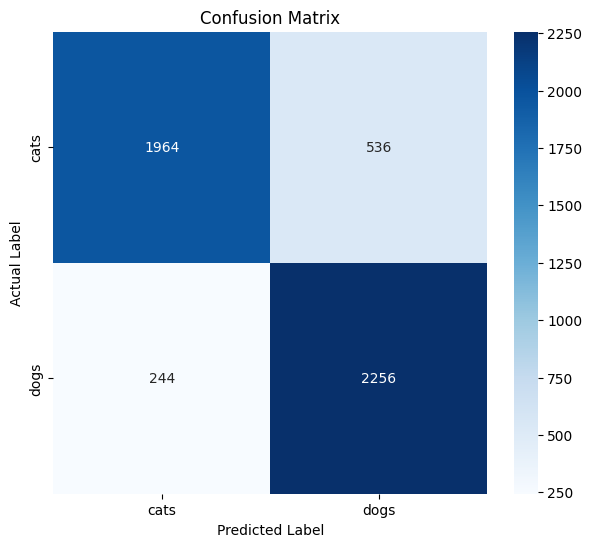

Total Incorrect Predictions: 780


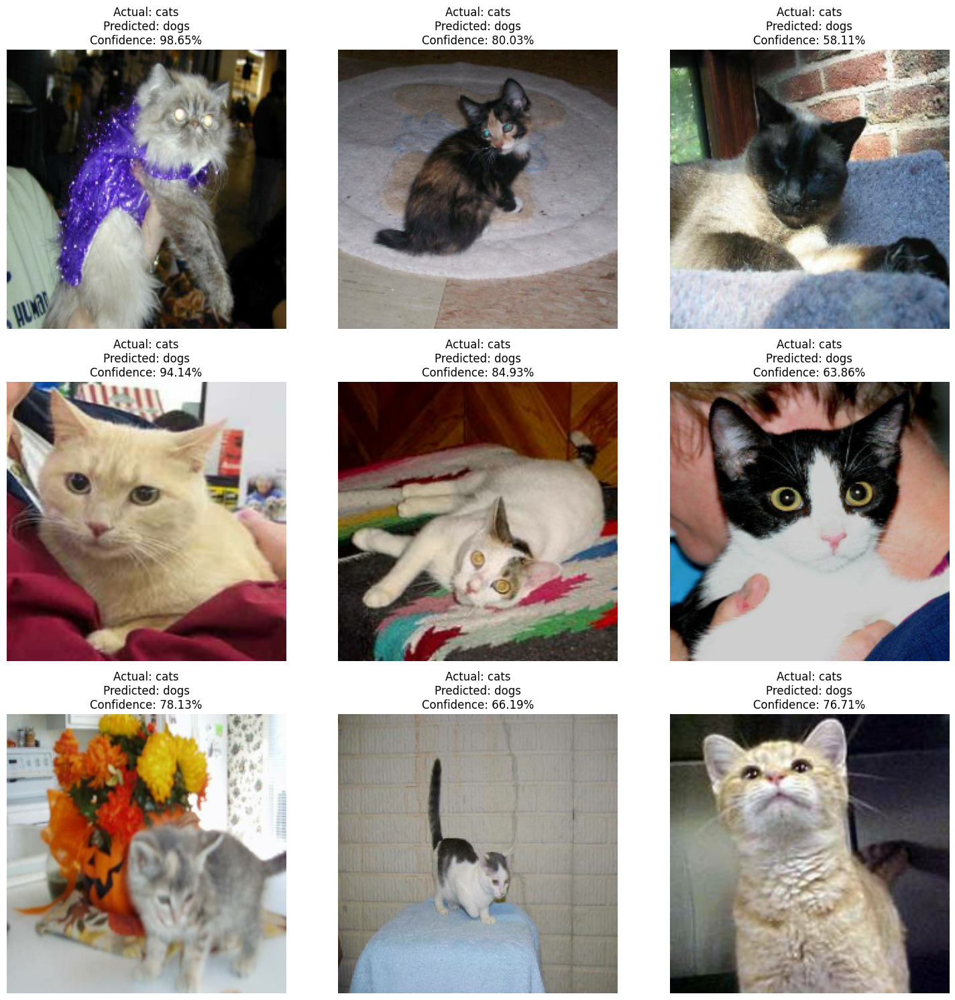

In [ ]:
error_analysis(
    model=custom_cnn,
    test_dataset=test_dataset,
    class_names=class_names,
    num_errors=9
)

## MobileNetV2

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        cats       0.99      0.98      0.99      2500
        dogs       0.98      0.99      0.99      2500

    accuracy                           0.99      5000
   macro avg       0.99      0.99      0.99      5000
weighted avg       0.99      0.99      0.99      5000



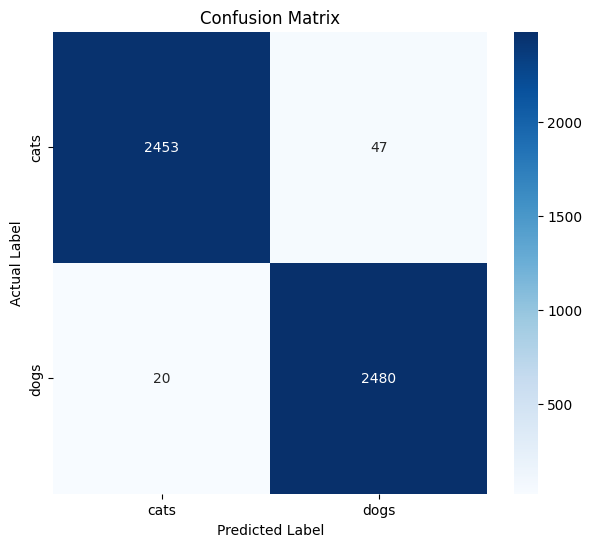

Total Incorrect Predictions: 67


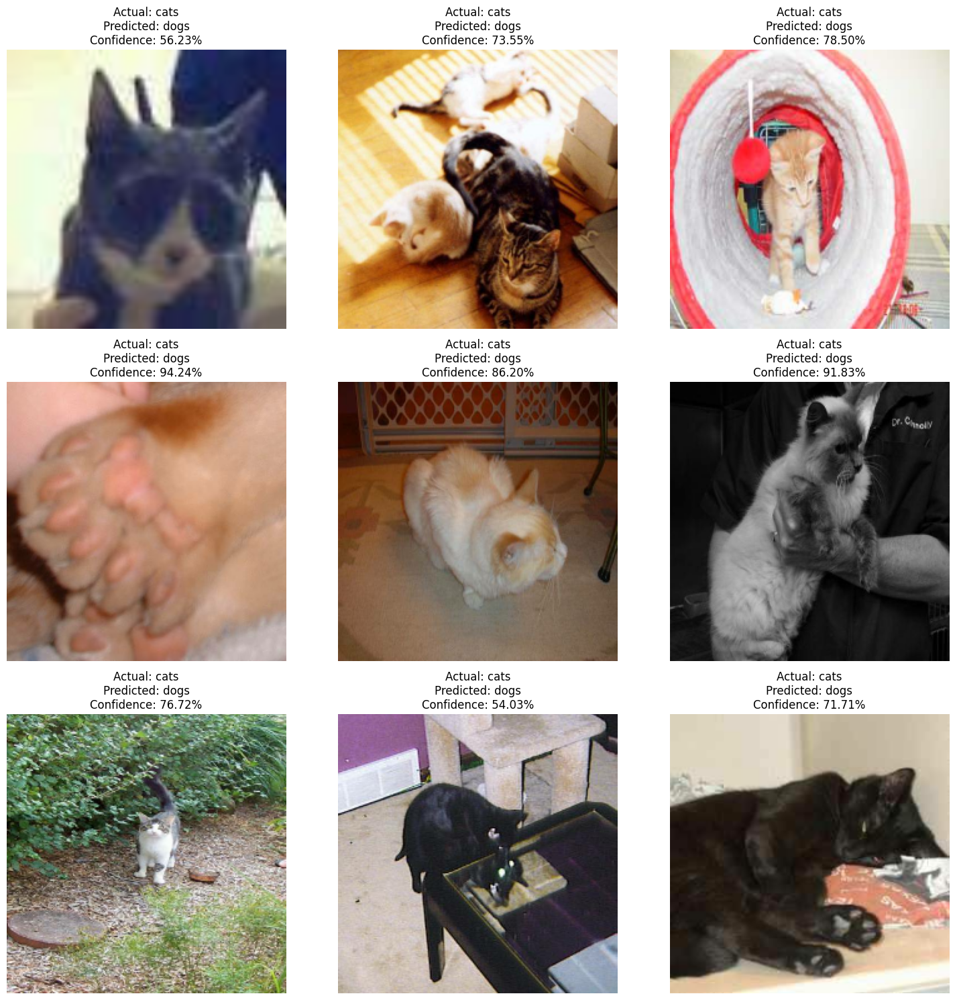

In [ ]:
error_analysis(
    model=mobilenet_model,
    test_dataset=test_dataset,
    class_names=class_names,
    num_errors=9
)

## EfficientNetB0

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        cats       0.99      0.99      0.99      2500
        dogs       0.99      0.99      0.99      2500

    accuracy                           0.99      5000
   macro avg       0.99      0.99      0.99      5000
weighted avg       0.99      0.99      0.99      5000



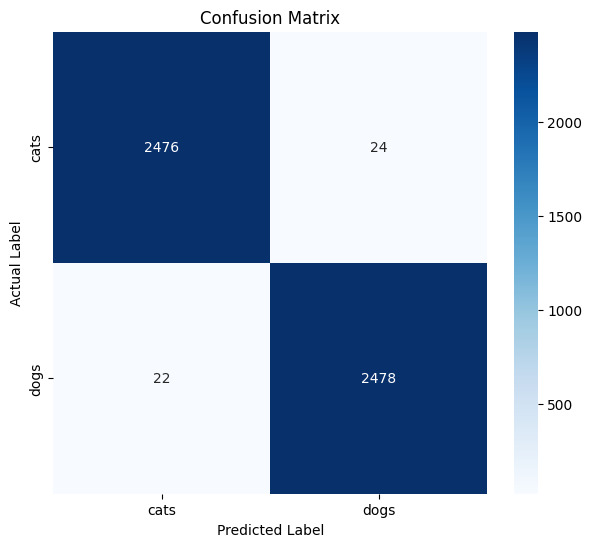

Total Incorrect Predictions: 46


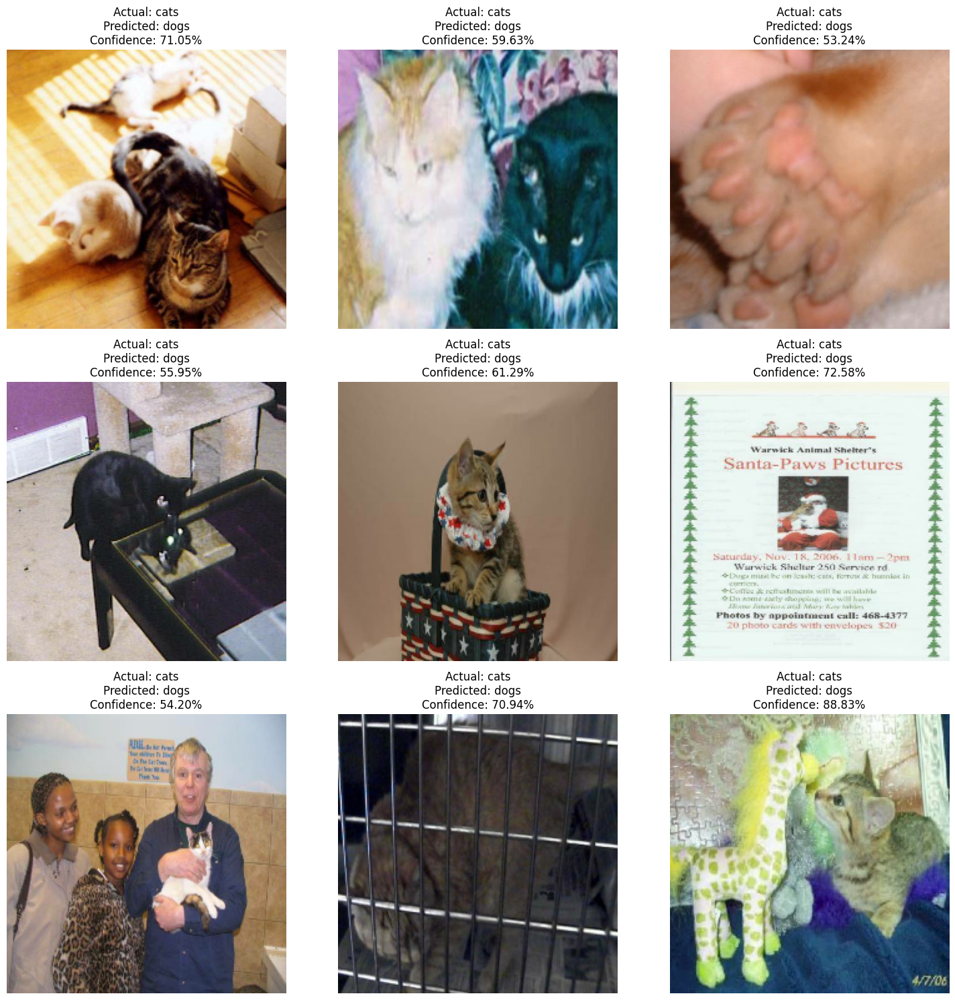

In [ ]:
error_analysis(
    model=efficientnet_model,
    test_dataset=test_dataset,
    class_names=class_names,
    num_errors=9
)

# Store Model and Best Model in google drive

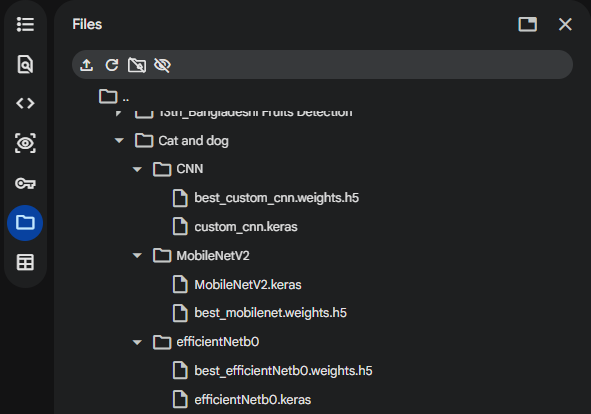